# Лабораторная работа №2: Классификация

Датасет Titanic. Цель — предсказать `Survived` (1 — выжил, 0 — нет).
Основная метрика — **F1 для класса 1**, порог качества **F1 > 0.70**.

In [ ]:
%pip install -q pandas numpy matplotlib seaborn "scikit-learn>=1.4"

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

warnings.simplefilter("ignore")
%matplotlib inline
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
RANDOM_STATE = 42

## 1. Первичный анализ данных

### 1.1 Загрузка

In [3]:
import os

URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
PATH = "data/titanic.csv"
df = pd.read_csv(PATH if os.path.exists(PATH) else URL)
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


891 пассажир, 12 столбцов: `Survived` — цель, остальные 11 — кандидаты в признаки.

### 1.2 Типы, пропуски, дубликаты, число уникальных значений

In [4]:
info = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "% пропусков": (df.isna().mean() * 100).round(1),
    "уникальных": df.nunique(),
})
print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
info

Полных дубликатов: 0
Дубликатов без PassengerId: 0


,тип,пропусков,% пропусков,уникальных
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,str,0,0.0,891
Sex,str,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,str,0,0.0,681
Fare,float64,0,0.0,248


**Выводы:**
- Дубликатов нет.
- **Пропуски:** `Age` — 20%, `Cabin` — 77%, `Embarked` — 2 строки.
- **Идентификаторы:** `PassengerId` и `Name` уникальны у каждого пассажира, у `Ticket` 681 значение на 891 строку, у `Cabin` 147 значений на 204 известных. Если дать их модели, она сможет запомнить конкретных людей вместо общих закономерностей.
- **Требуют обработки:** `Sex` и `Embarked` — строки, нужна кодировка. `Pclass` — число, но по смыслу это категория (класс билета).

### 1.3 Целевая переменная

          число   доля
Survived              
0           549  0.616
1           342  0.384


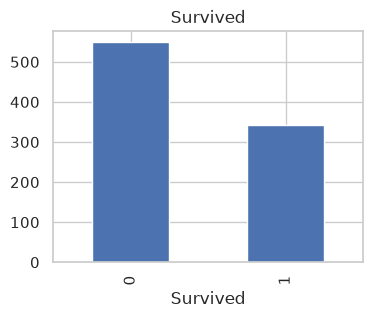

In [5]:
counts = df["Survived"].value_counts()
print(pd.DataFrame({"число": counts, "доля": counts / len(df)}).round(3))

counts.plot(kind="bar", figsize=(4, 3), title="Survived")
plt.show()

Выжило 38.4%, классы несбалансированы умеренно. Модель «все погибли» уже даёт accuracy 0.616, ни разу не найдя выжившего. Поэтому основная метрика — F1, а разбиение делаем стратифицированным.

### 1.4 Выживаемость по категориальным признакам

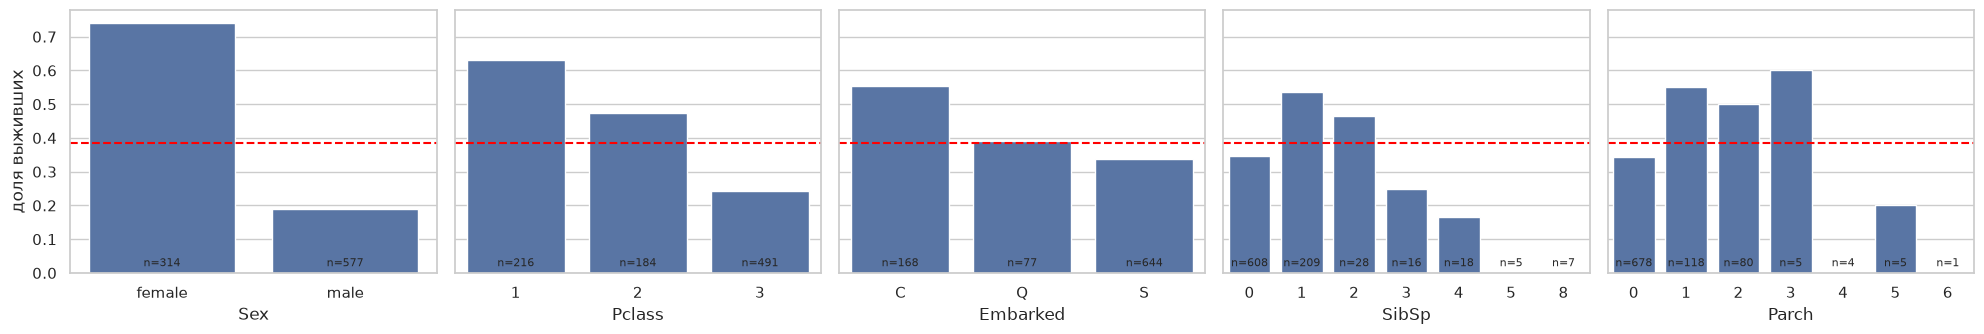

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked", "SibSp", "Parch"]):
    sizes = df.groupby(col)["Survived"].size()
    sns.barplot(data=df, x=col, y="Survived", order=sizes.index, errorbar=None, ax=ax)
    ax.axhline(df["Survived"].mean(), color="red", ls="--")
    for i, n in enumerate(sizes):
        ax.text(i, 0.02, f"n={n}", ha="center", fontsize=8)
axes[0].set_ylabel("доля выживших")
plt.tight_layout()
plt.show()

In [7]:
print(pd.crosstab(df["Sex"], df["Pclass"], values=df["Survived"], aggfunc="mean").round(2))
print("\nДоля классов среди севших в каждом порту:")
print(pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2))

Pclass     1     2     3
Sex                     
female  0.97  0.92  0.50
male    0.37  0.16  0.14

Доля классов среди севших в каждом порту:
Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55


**Выводы** (красная линия — средняя выживаемость 0.38):
- **Sex** — самый сильный фактор: выжили 74% женщин и 19% мужчин.
- **Pclass:** 63% / 47% / 24% для 1/2/3 класса.
- **Пол × класс:** женщины 1–2 класса выжили почти все (0.97 и 0.92), женщины 3 класса — наполовину (0.50), мужчины 2–3 класса — около 15%. В группах «женщины 3 класса» и «мужчины 1 класса» (0.37) исход ближе всего к 50/50, здесь стоит ждать ошибок модели.
- **Embarked:** из Шербура (C) выжили 55%. Но в Шербуре 51% севших — пассажиры 1 класса, а в Квинстауне (Q) 94% — пассажиры 3 класса. То есть порт в основном повторяет информацию о классе.
- **SibSp, Parch:** выживаемость выше у пассажиров с 1–2 родственниками, ниже у одиночек и больших семей. Групп с 4+ родственниками мало (n ≤ 18), выводы по ним ненадёжны.

### 1.5 Числовые признаки: Age и Fare

      count  mean   std  min   25%   50%   75%    max
Age   714.0  29.7  14.5  0.4  20.1  28.0  38.0   80.0
Fare  891.0  32.2  49.7  0.0   7.9  14.5  31.0  512.3


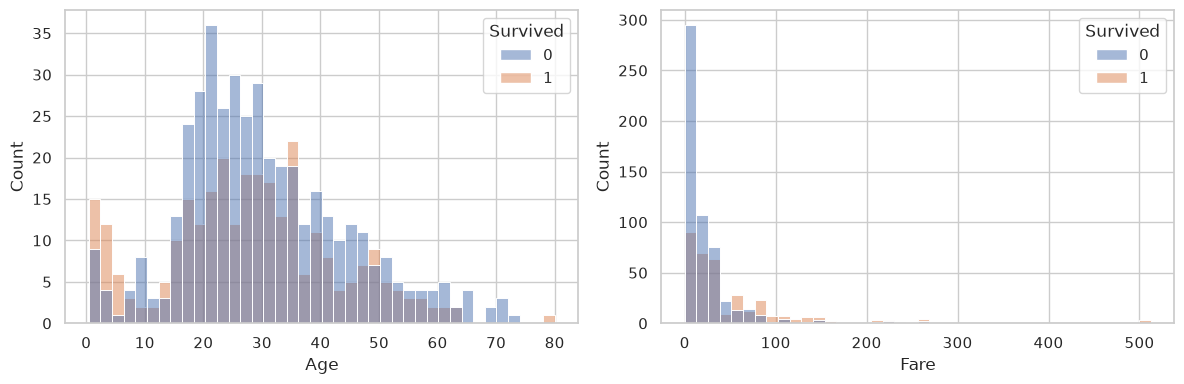

In [8]:
print(df[["Age", "Fare"]].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["Age", "Fare"]):
    sns.histplot(data=df, x=col, hue="Survived", bins=40, ax=ax)
plt.tight_layout()
plt.show()

In [9]:
age_group = pd.cut(df["Age"], [0, 12, 18, 30, 50, 80])
print(df.groupby(age_group, observed=True)["Survived"].agg(["mean", "size"]).round(2))
print("\nВозраст неизвестен:", df.loc[df["Age"].isna(), "Survived"].agg(["mean", "size"]).round(2).to_dict())
print("Каюта известна:    ", df.groupby(df["Cabin"].notna())["Survived"].mean().round(2).to_dict())

          mean  size
Age                 
(0, 12]   0.58    69
(12, 18]  0.43    70
(18, 30]  0.36   270
(30, 50]  0.42   241
(50, 80]  0.34    64

Возраст неизвестен: {'mean': 0.29, 'size': 177.0}
Каюта известна:     {False: 0.3, True: 0.67}


In [10]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
df[num_cols].corr()["Survived"].drop("Survived").sort_values().round(2)

Pclass   -0.34
Age      -0.08
SibSp    -0.04
Parch     0.08
Fare      0.26
Name: Survived, dtype: float64

**Выводы:**
- **Fare:** сильный правый хвост (медиана 14.5, максимум 512). Корреляция с выживанием +0.26: дорогой билет связан с высоким классом (корреляция Pclass с Survived −0.34).
- **Age:** линейная корреляция слабая (−0.08), но зависимость нелинейная: дети до 12 лет выжили в 58% случаев, остальные группы — 34–43%.
- **Пропуск Age неслучаен:** среди пассажиров без возраста выжили только 29%.
- **Cabin:** выжили 67% пассажиров с известной каютой и 30% без неё. Но это в основном отражает класс, а сами номера кают почти уникальны.

### 1.6 Выводы EDA

| Признак | Что увидели | Решение |
|---|---|---|
| `Sex` | главный фактор (74% vs 19%) | one-hot |
| `Pclass` | 63% / 47% / 24% | one-hot (категория) |
| `Fare` | связан с классом, длинный хвост | оставить, масштабировать для SVM/KNN |
| `Age` | 20% пропусков, дети выживали чаще | медиана по train |
| `SibSp`, `Parch` | слабый нелинейный эффект | оставить |
| `Embarked` | 2 пропуска, эффект в основном через класс | проверить на CV (п. 2.4) |
| `PassengerId`, `Name` | уникальны у каждого | удалить: модель запомнит конкретных людей |
| `Ticket` | 681 значение на 891 строку | удалить: почти идентификатор |
| `Cabin` | 77% пропусков, номера почти уникальны | удалить |

## 2. Подготовка данных

### 2.1 Признаки и разбиение

In [11]:
num_features = ["Age", "SibSp", "Parch", "Fare"]
cat_features = ["Pclass", "Sex", "Embarked"]

X = df[num_features + cat_features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("train:", X_train.shape, " test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True),
              "test": y_test.value_counts(normalize=True)}).round(3)

train: (712, 7)  test: (179, 7)


,train,test
Survived,,
0,0.617,0.615
1,0.383,0.385


- **Признаки:** 4 числовых и 3 категориальных, идентификаторы удалены.
- **Разбиение:** 80/20 (712 / 179), `stratify=y` сохраняет долю выживших 38% в обеих частях. `random_state=42` фиксирует разбиение, и все модели обучаются и оцениваются на одном и том же.
- Тест не используется ни при подборе параметров, ни при обучении преобразований.

### 2.2 Обработка пропусков и категорий

In [12]:
def make_preprocess(scale, num, cat):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    cat_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                 ("ohe", OneHotEncoder(handle_unknown="ignore"))]
    return ColumnTransformer([("num", Pipeline(num_steps), num),
                              ("cat", Pipeline(cat_steps), cat)],
                             verbose_feature_names_out=False)


prep_all = make_preprocess(False, num_features, cat_features)
Xt = prep_all.fit_transform(X_train)
print(X_train.shape, "->", Xt.shape)
print(list(prep_all.get_feature_names_out()))

(712, 7) -> (712, 12)
['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


- **Age** → медиана. Медиана устойчива к выбросам и асимметрии, а 20% пропусков слишком много, чтобы удалять строки.
- **Embarked** → самое частое значение (`S`): пропусков всего 2.
- **Sex, Embarked, Pclass** → one-hot. Порядковый код вроде S=0, C=1, Q=2 навязал бы несуществующий порядок. `handle_unknown="ignore"` защищает от категорий, которых не было в train.
- Все шаги собраны в `ColumnTransformer` внутри `Pipeline`. Поэтому медианы, мода и scaler вычисляются только по train, а при CV — только по обучающим фолдам. Утечки из теста нет.
- Итого 7 исходных столбцов → 12 признаков (4 числовых + 8 one-hot), как в лекции.

### 2.3 Масштабирование

In [13]:
pd.DataFrame(Xt[:, :len(num_features)], columns=num_features).describe().loc[["mean", "std", "max"]].round(1)

,Age,SibSp,Parch,Fare
mean,29.6,0.5,0.4,31.8
std,13.0,1.1,0.8,48.1
max,80.0,8.0,6.0,512.3


Масштабы признаков сильно различаются: у `Fare` std 48 и максимум 512, у `SibSp` std 1.1.

- **SVM (RBF) и KNN** считают расстояния между объектами. Без масштабирования расстояние почти целиком определяется `Fare`, и остальные признаки фактически игнорируются. Для них используем `preprocess_scaled` со `StandardScaler`.
- **DT, RF, GB** делят данные порогами по одному признаку. Масштабирование не меняет порядок значений, поэтому не меняет и разбиения. Для них используем `preprocess_tree`.

### 2.4 Нужен ли Embarked

In [14]:
default_models = {
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "Random Forest": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), False),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), False),
    "SVM": (SVC(random_state=RANDOM_STATE), True),
    "KNN": (KNeighborsClassifier(), True),
}
rows = {}
for name, (model, scale) in default_models.items():
    for label, cat in [("с Embarked", cat_features), ("без Embarked", ["Pclass", "Sex"])]:
        pipe = Pipeline([("prep", make_preprocess(scale, num_features, cat)), ("model", model)])
        rows.setdefault(name, {})[label] = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="f1").mean()
pd.DataFrame(rows).T.round(3)

,с Embarked,без Embarked
Decision Tree,0.695,0.713
Random Forest,0.737,0.753
Gradient Boosting,0.753,0.768
SVM,0.745,0.757
KNN,0.718,0.748


In [15]:
cat_features = ["Pclass", "Sex"]
preprocess_tree = make_preprocess(False, num_features, cat_features)    # DT, RF, GB
preprocess_scaled = make_preprocess(True, num_features, cat_features)   # SVM, KNN
feature_names = preprocess_tree.fit(X_train).get_feature_names_out()
print(list(feature_names))

['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_1', 'Pclass_2', 'Pclass_3', 'Sex_female', 'Sex_male']


Без `Embarked` F1 на CV растёт у **всех пяти** моделей (+0.012…+0.030), сильнее всего у KNN (+0.030) и дерева (+0.018). Почему:
- порт почти не добавляет информации сверх класса (см. п. 1.4);
- 3 one-hot столбца порта для KNN и SVM входят в расстояние с тем же весом, что и пол, и добавляют шум;
- деревьям они дают лишние случайные разбиения.

Решение принято только по CV на train, тест не использовался. Дальше все модели обучаются на одинаковом наборе из 9 признаков.

## 3. Метрики и baseline

Класс 1 — «выжил».

| | Формула | Смысл в задаче |
|---|---|---|
| Accuracy | (TP+TN) / N | доля верных ответов |
| Precision | TP / (TP+FP) | из тех, кого назвали выжившими, сколько выжили |
| Recall | TP / (TP+FN) | из всех выживших сколько нашли |
| F1 | 2PR / (P+R) | баланс Precision и Recall |

- **FP** — модель сказала «выжил», а пассажир погиб (ложная тревога).
- **FN** — модель сказала «погиб», а пассажир выжил (пропуск).

Ни одна из ошибок здесь не дороже другой, поэтому F1 удобна: она наказывает за перекос в любую сторону.

Функция `evaluate` считает 4 метрики на train и test, сохраняет тестовые в `results` и рисует confusion matrix. Функция `search` подбирает гиперпараметры через `GridSearchCV` (5-fold стратифицированная CV, метрика F1) только на train.

In [16]:
results = {}


def metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1": f1_score(y_true, y_pred, zero_division=0)}


def evaluate(name, model):
    test = metrics(y_test, model.predict(X_test))
    train = metrics(y_train, model.predict(X_train))
    results[name] = test
    print(pd.DataFrame({"train": train, "test": test}).T.round(3))

    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=["0 погиб", "1 выжил"]).plot(cmap="Blues", colorbar=False)
    plt.title(name)
    plt.show()


def search(name, preprocess, model, grid):
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    gs = GridSearchCV(pipe, {f"model__{k}": v for k, v in grid.items()},
                      cv=CV, scoring="f1").fit(X_train, y_train)
    print(name, "лучшие параметры:", {k.replace("model__", ""): v for k, v in gs.best_params_.items()})
    print(f"F1 CV: {gs.best_score_:.3f}")
    return gs.best_estimator_

### 3.1 Dummy baseline

       Accuracy  Precision  Recall   F1
train     0.617        0.0     0.0  0.0
test      0.615        0.0     0.0  0.0


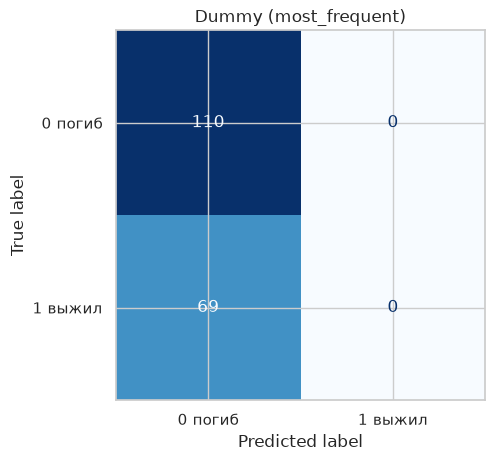

In [17]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
evaluate("Dummy (most_frequent)", dummy)

Baseline всегда отвечает «погиб». Accuracy 0.615 равна доле класса 0, а Precision, Recall и F1 равны 0: не найден ни один выживший (вся нижняя строка матрицы — FN). Значит, accuracy около 0.6 ещё ничего не говорит о качестве. Модель должна набрать F1 > 0 и превзойти 0.615 по accuracy.

## 4. Модели

Гиперпараметры подбираются `GridSearchCV` по F1 на 5-fold CV внутри train. Тест используется только для итоговой оценки.

### 4.1 Decision Tree

In [18]:
dt_full = Pipeline([("prep", preprocess_tree),
                    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]).fit(X_train, y_train)
print("Дерево без ограничений, глубина", dt_full[-1].get_depth())
print(f"F1 train: {f1_score(y_train, dt_full.predict(X_train)):.3f}  "
      f"F1 CV: {cross_val_score(dt_full, X_train, y_train, cv=CV, scoring='f1').mean():.3f}  "
      f"F1 test: {f1_score(y_test, dt_full.predict(X_test)):.3f}")

Дерево без ограничений, глубина 23


F1 train: 0.978  F1 CV: 0.713  F1 test: 0.763


DT лучшие параметры: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 10}
F1 CV: 0.742
       Accuracy  Precision  Recall     F1
train     0.860      0.859   0.758  0.805
test      0.788      0.754   0.667  0.708


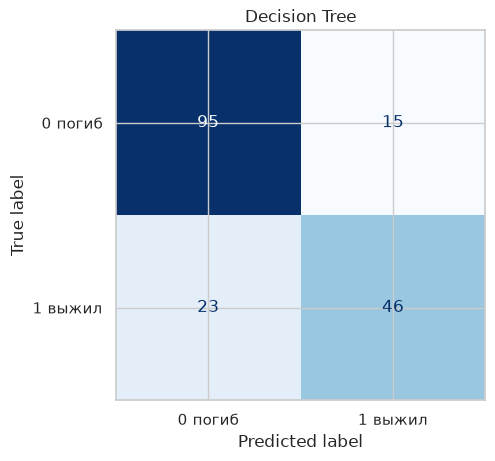

In [19]:
dt = search("DT", preprocess_tree, DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"criterion": ["gini", "entropy"], "max_depth": [2, 3, 4, 5, 6, 8, None],
             "min_samples_leaf": [1, 3, 5, 10, 20]})
evaluate("Decision Tree", dt)

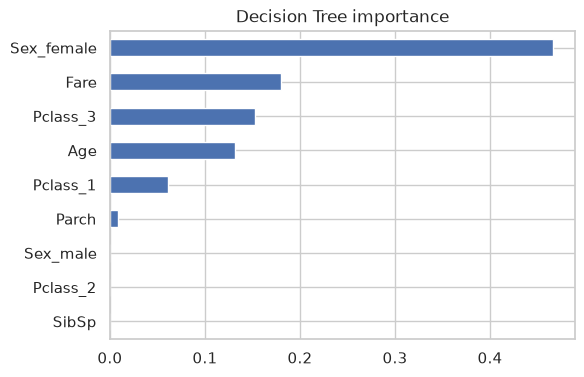

Sex_female    0.466
Fare          0.180
Pclass_3      0.153
Age           0.131
Pclass_1      0.062
Parch         0.008
SibSp         0.000
Pclass_2      0.000
Sex_male      0.000
dtype: float64

In [20]:
def importance(model):
    return pd.Series(model[-1].feature_importances_, index=feature_names).sort_values(ascending=False)


def plot_importance(imp, title):
    imp.sort_values().plot(kind="barh", figsize=(6, 4), title=title)
    plt.show()


imp_dt = importance(dt)
plot_importance(imp_dt, "Decision Tree importance")
imp_dt.round(3)

**Переобучение:**
- **Дерево без ограничений** (глубина 23): F1 train 0.978 при CV 0.713. Дерево почти запомнило обучающую выборку, это явное переобучение.
- **Подобранное дерево** (`criterion="entropy"`, `max_depth=8`, `min_samples_leaf=10`): CV 0.742, train 0.805, test 0.708. Разрыв train–test 0.10: переобучение уменьшилось, но осталось.
- На тесте дерево без ограничений случайно получило больше (0.763). Но тест — всего 179 объектов, а выбирать модель по тесту нельзя, поэтому ориентируемся на CV.

**Важность признаков:** `Sex_female` 0.47, `Fare` 0.18, `Pclass_3` 0.15, `Age` 0.13. У `Sex_male` важность 0: столбец дублирует `Sex_female` (`Sex_male = 1 − Sex_female`), и дерево использует только один из них. `SibSp` дерево не использует совсем.

### 4.2 Random Forest

RF лучшие параметры: {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1}
F1 CV: 0.781
       Accuracy  Precision  Recall     F1
train     0.924      0.947   0.850  0.896
test      0.816      0.810   0.681  0.740


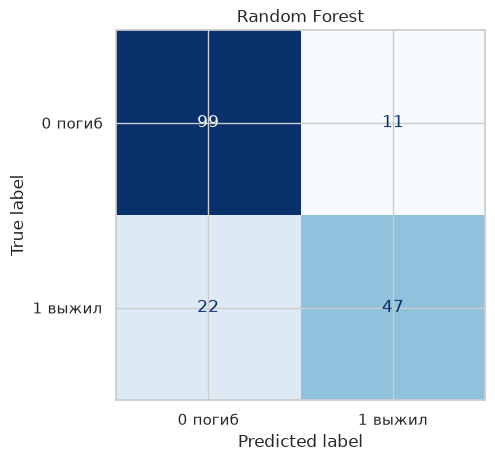

In [21]:
rf = search("RF", preprocess_tree, RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
            {"max_depth": [4, 6, 8, None], "min_samples_leaf": [1, 3, 5], "max_features": ["sqrt", 0.5]})
evaluate("Random Forest", rf)

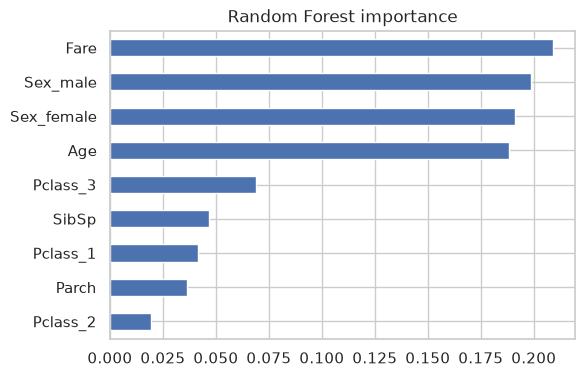

,DT,RF
Fare,0.180,0.209
Sex_male,0.000,0.199
Sex_female,0.466,0.191
Age,0.131,0.188
Pclass_3,0.153,0.069
SibSp,0.000,0.047
Pclass_1,0.062,0.042
Parch,0.008,0.036
Pclass_2,0.000,0.019


In [22]:
imp_rf = importance(rf)
plot_importance(imp_rf, "Random Forest importance")
pd.DataFrame({"DT": imp_dt, "RF": imp_rf}).sort_values("RF", ascending=False).round(3)

- **Качество:** CV 0.781 — лучший результат среди всех моделей. Test F1 0.740, Precision 0.81, Recall 0.68.
- **Переобучение:** разрыв train–test 0.16 больше, чем у подобранного дерева. Каждое дерево леса глубокое (`min_samples_leaf=1`) и сильно подгоняется под train, но усреднение 300 деревьев даёт лучшее качество на новых данных (CV 0.781 против 0.742). Сам по себе разрыв ещё не значит, что модель хуже.
- **Важность признаков:** лидеры те же, что у DT: пол (`Sex_male` + `Sex_female` = 0.39), `Fare`, `Age`. Отличия:
  - лес распределяет важность ровнее: `Fare` 0.21 и `Age` 0.19 почти равны полу;
  - класс (`Pclass_3`) получает меньше: 0.07 против 0.15 у дерева;
  - `SibSp` и `Parch` получают ненулевой вес, потому что в каждом узле леса доступна только часть признаков.

### 4.3 Gradient Boosting

GB лучшие параметры: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}
F1 CV: 0.777
       Accuracy  Precision  Recall     F1
train     0.940      0.960   0.879  0.918
test      0.838      0.845   0.710  0.772


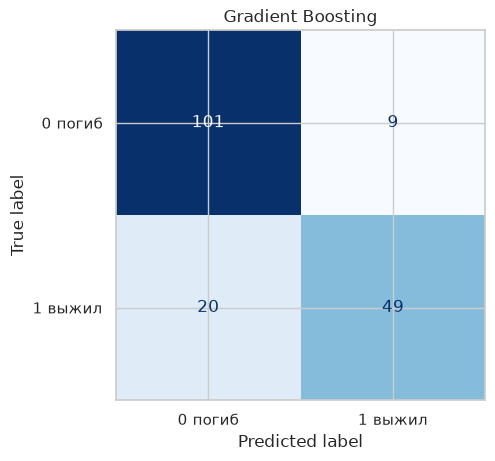

In [23]:
gb = search("GB", preprocess_tree, GradientBoostingClassifier(random_state=RANDOM_STATE),
            {"learning_rate": [0.01, 0.05, 0.1], "n_estimators": [100, 300], "max_depth": [2, 3, 4]})
evaluate("Gradient Boosting", gb)

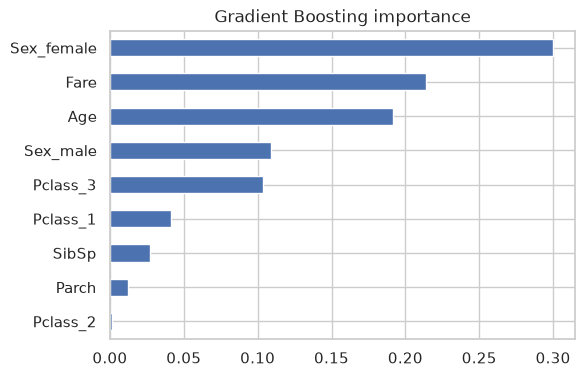

,RF,GB
Sex_female,0.191,0.300
Fare,0.209,0.214
Age,0.188,0.192
Sex_male,0.199,0.109
Pclass_3,0.069,0.103
Pclass_1,0.042,0.041
SibSp,0.047,0.027
Parch,0.036,0.012
Pclass_2,0.019,0.002


In [24]:
imp_gb = importance(gb)
plot_importance(imp_gb, "Gradient Boosting importance")
pd.DataFrame({"RF": imp_rf, "GB": imp_gb}).sort_values("GB", ascending=False).round(3)

- **Качество:** CV 0.777, test F1 0.772 — лучший результат на тесте.
- **Сравнение с RF:** по CV модели равны (0.777 против 0.781), на тесте GB выше на 0.03. Такая разница сравнима с шумом теста из 179 объектов.
- **Переобучение:** разрыв train–test 0.15, как у RF.
- **Важность признаков** близка к RF: пол 0.41, `Fare` 0.21, `Age` 0.19, класс 0.15. Отличие в том, что GB, как и дерево, сосредотачивает важность пола в одном столбце `Sex_female` (0.30): деревья бустинга видят все признаки, и при прочих равных берут первый.

### 4.4 SVM

In [25]:
for name, prep in [("без масштабирования", preprocess_tree), ("со StandardScaler", preprocess_scaled)]:
    m = Pipeline([("prep", prep), ("model", SVC(random_state=RANDOM_STATE))]).fit(X_train, y_train)
    print(f"SVC по умолчанию {name}: F1 test {f1_score(y_test, m.predict(X_test)):.3f}")

SVC по умолчанию без масштабирования: F1 test 0.320
SVC по умолчанию со StandardScaler: F1 test 0.754


SVM лучшие параметры: {'C': 3, 'gamma': 0.1}
F1 CV: 0.763
       Accuracy  Precision  Recall     F1
train     0.836      0.828   0.722  0.771
test      0.821      0.803   0.710  0.754


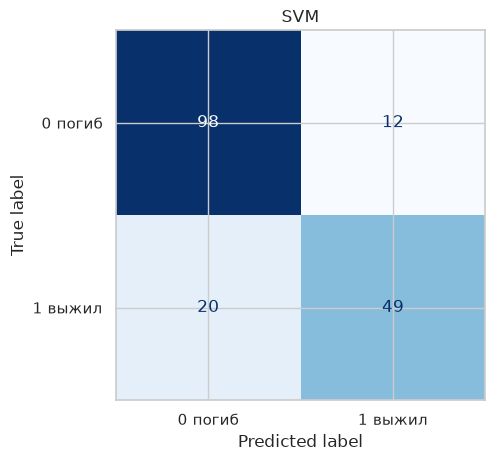

In [26]:
svm = search("SVM", preprocess_scaled, SVC(random_state=RANDOM_STATE),
             {"C": [0.1, 0.3, 1, 3, 10], "gamma": ["scale", 0.01, 0.03, 0.1, 0.3]})
evaluate("SVM", svm)

**Масштабирование обязательно.** Без него F1 0.320, с ним 0.754. RBF-ядро $\exp(-\gamma\|x-z\|^2)$ зависит от расстояния, а в расстоянии без масштабирования доминирует `Fare`.

**Подобранная модель** (`C=3`, `gamma=0.1`): CV 0.763, train 0.771, test 0.754. Разрыва почти нет, значит переобучения нет: гладкая граница с регуляризацией.

### 4.5 KNN

In [27]:
for name, prep in [("без масштабирования", preprocess_tree), ("со StandardScaler", preprocess_scaled)]:
    m = Pipeline([("prep", prep), ("model", KNeighborsClassifier())]).fit(X_train, y_train)
    print(f"KNN (k=5) {name}: F1 test {f1_score(y_test, m.predict(X_test)):.3f}")

KNN (k=5) без масштабирования: F1 test 0.571
KNN (k=5) со StandardScaler: F1 test 0.761


KNN лучшие параметры: {'n_neighbors': 3, 'weights': 'uniform'}
F1 CV: 0.757
       Accuracy  Precision  Recall     F1
train     0.883      0.868   0.821  0.844
test      0.810      0.769   0.725  0.746


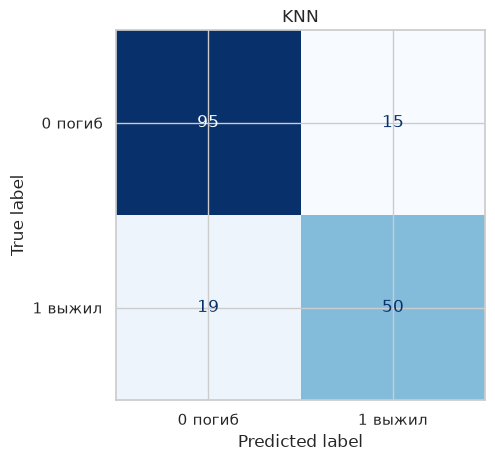

In [28]:
knn = search("KNN", preprocess_scaled, KNeighborsClassifier(),
             {"n_neighbors": [3, 5, 7, 9, 11, 15, 21], "weights": ["uniform", "distance"]})
evaluate("KNN", knn)

**Масштаб особенно важен.** Соседи ищутся по евклидову расстоянию. Без масштабирования разница в цене билета в 50 весит в 50 раз больше, чем разница по полу (0 или 1), и соседи подбираются почти только по `Fare`. Поэтому F1 0.571 без масштабирования против 0.761 с ним.

**Подобранная модель** (`k=3`): CV 0.757, train 0.844, test 0.746. Разрыв 0.10 — плата за малое `k`: граница очень локальная, высокий разброс.

## 5. Итоговое сравнение

In [29]:
table = pd.DataFrame(results).T.round(3)
table["F1 > 0.70"] = table["F1"] > 0.70
table.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1,F1 > 0.70
Gradient Boosting,0.838,0.845,0.710,0.772,True
SVM,0.821,0.803,0.710,0.754,True
KNN,0.810,0.769,0.725,0.746,True
Random Forest,0.816,0.810,0.681,0.740,True
Decision Tree,0.788,0.754,0.667,0.708,True
Dummy (most_frequent),0.615,0.000,0.000,0.000,False


**Порог F1 > 0.70 прошли все пять моделей:** GB 0.772, SVM 0.754, KNN 0.746, RF 0.740, DT 0.708. Dummy — 0.

**Причины различий:**
- **Ансамбли деревьев (RF, GB)** лучше всех по CV (0.781 и 0.777). Они учитывают взаимодействия признаков (пол × класс × возраст), которые EDA показал важными.
- **SVM и KNN** немного ниже (CV 0.763 и 0.757). Обе модели зависят от расстояний, и на маленькой выборке это работает хорошо после масштабирования.
- **DT** хуже всех (CV 0.742): одно дерево нестабильно и либо переобучается, либо, если его сильно ограничить, упрощает зависимость.
- **Порядок на тесте и на CV различается** (RF первый по CV, но четвёртый на тесте). Разницы в 0.01–0.03 сравнимы с шумом теста: в нём 69 выживших, и одна ошибка меняет F1 примерно на 0.01.
- **Precision выше Recall** у всех моделей. Модели чаще пропускают выживших (FN), чем ошибочно называют погибших выжившими (FP): выживших меньше (38%), а порог стоит на 0.5.

## 6. Feature Importance

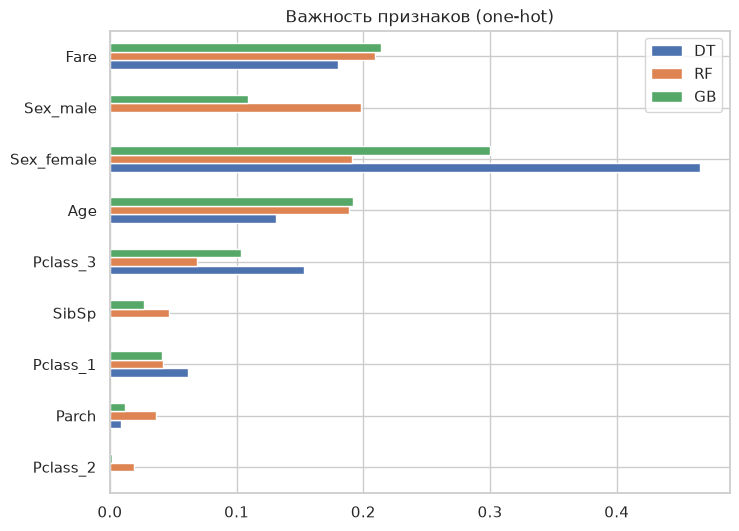

,DT,RF,GB
Sex,0.466,0.390,0.409
Fare,0.180,0.209,0.214
Age,0.131,0.188,0.192
Pclass,0.215,0.130,0.147
SibSp,0.000,0.047,0.027
Parch,0.008,0.036,0.012


In [30]:
fi = pd.DataFrame({"DT": imp_dt, "RF": imp_rf, "GB": imp_gb})
fi.sort_values("RF").plot(kind="barh", figsize=(8, 6), title="Важность признаков (one-hot)")
plt.show()

# суммируем one-hot столбцы обратно в исходные признаки
source = {f: next(c for c in num_features + cat_features if f == c or f.startswith(c + "_"))
          for f in feature_names}
fi_src = fi.groupby(source).sum().sort_values("RF", ascending=False)
fi_src.round(3)

**Главные признаки** у всех трёх моделей: **Sex** (0.39–0.47) — на первом месте с большим отрывом. Дальше **Fare** (0.18–0.21), **Age** (0.13–0.19), **Pclass** (0.13–0.22). `SibSp` и `Parch` вместе дают не больше 0.08.

**DT, RF и GB:**
- RF и GB почти совпадают: Sex ≫ Fare ≈ Age > Pclass.
- У одиночного дерева класс на втором месте (0.22): дерево делает одно разбиение по `Pclass_3`, и вся важность класса собирается в нём. Ансамбли делят эту информацию с `Fare`, который с классом связан.
- Внутри one-hot: DT и GB берут один столбец пола, RF — оба. После суммирования по исходным признакам разница исчезает.

**Сравнение с EDA:**
- **Sex** на первом месте — так же, как в EDA (74% vs 19%).
- **Pclass** в EDA сильнее Fare (корреляция −0.34 против +0.26), а у ансамблей наоборот. Причина: Fare частично дублирует информацию о классе, а у непрерывного признака больше возможных порогов. Встроенная важность деревьев завышает признаки с большим числом уникальных значений.
- **Age:** корреляция −0.08, а важность высокая. Корреляция видит только линейную связь, а деревья ловят нелинейный эффект «дети выживали чаще». Частично это то же завышение для непрерывных признаков.
- **SibSp, Parch** слабые и в EDA, и у моделей. **Embarked** исключён по CV (п. 2.4), что согласуется с EDA: порт повторял информацию о классе.

**Можно ли считать важный признак причиной выживания?** Нет:
1. Важность показывает, какие признаки полезны модели для предсказания, а не что влияет на исход.
2. Пол важен не сам по себе: причина — правило «женщины и дети первыми» при посадке в шлюпки. Пол лишь указывает на него.
3. Fare сам по себе не спасает: он связан с классом, а класс — с расположением кают и доступом к шлюпкам.
4. Коррелирующие признаки (Fare и Pclass) делят важность между собой, а встроенная важность смещена к непрерывным признакам.

## 7. Анализ ошибок лучшей модели (Gradient Boosting)

In [31]:
best = gb
pred = best.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"Погибших распознано: {tn / (tn + fp):.0%}, выживших найдено (Recall): {tp / (tp + fn):.0%}")

TN=101  FP=9  FN=20  TP=49
Погибших распознано: 92%, выживших найдено (Recall): 71%


In [32]:
test = df.loc[X_test.index].copy()
test["pred"] = pred
test["P(выжил)"] = best.predict_proba(X_test)[:, 1].round(2)
test["FP"] = (test["pred"] == 1) & (test["Survived"] == 0)
test["FN"] = (test["pred"] == 0) & (test["Survived"] == 1)

groups = test.groupby(["Sex", "Pclass"]).agg(
    n=("Survived", "size"), выжило=("Survived", "mean"),
    предсказано_выжило=("pred", "mean"), FP=("FP", "sum"), FN=("FN", "sum"))
groups["ошибок, %"] = ((groups["FP"] + groups["FN"]) / groups["n"] * 100).round(0)
groups.round(2)

n  выжило  предсказано_выжило  FP  FN  ошибок, %
Sex    Pclass                                                   
female 1       15    0.93                1.00   1   0        7.0
       2       18    0.94                1.00   1   0        6.0
       3       28    0.50                0.46   2   3       18.0
male   1       30    0.37                0.33   4   5       30.0
       2       16    0.19                0.00   0   3       19.0
       3       72    0.14                0.03   1   9       14.0

**Типы ошибок:** FN (20) встречаются вдвое чаще FP (9). Модель распознаёт 92% погибших, но находит только 71% выживших.

**Где ошибается чаще всего** (группы на тесте небольшие, оценки грубые):
- **Мужчины 1 класса** — 30% ошибок (4 FP + 5 FN). Выжило 37%, модель предсказывает «выжил» 33% — почти верная доля, но часто не тем людям.
- **Женщины 3 класса** — 18% ошибок (2 FP + 3 FN), выжила половина.
- **Мужчины 2–3 класса** — модель предсказывает «погиб» почти всем, и редкие выжившие оказываются пропущены (3 + 9 FN).
- **Женщины 1–2 класса** — почти без ошибок.

Ошибки сосредоточены там, где EDA показал исход, близкий к 50/50 (мужчины 1 класса, женщины 3 класса), или где выживание — редкое исключение (мужчины 2–3 класса).

In [33]:
cols = ["Name", "Sex", "Pclass", "Age", "SibSp", "Parch", "Fare", "Survived", "pred", "P(выжил)"]
pd.concat([test[test["FP"]].head(4), test[test["FN"]].head(4)])[cols]

,Name,Sex,Pclass,Age,SibSp,Parch,Fare,Survived,pred,P(выжил)
536,"Butt, Major. Archibald Willingham",male,1,45.0,0,0,26.5500,0,1,0.72
698,"Thayer, Mr. John Borland",male,1,49.0,1,1,110.8833,0,1,0.86
297,"Allison, Miss. Helen Loraine",female,1,2.0,1,2,151.5500,0,1,0.98
593,"Bourke, Miss. Mary",female,3,NaN,0,2,7.7500,0,1,0.85
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,3,22.0,0,0,7.2250,1,0,0.09
559,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,3,36.0,1,0,17.4000,1,0,0.26
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,3,35.0,1,1,20.2500,1,0,0.25
712,"Taylor, Mr. Elmer Zebley",male,1,48.0,1,0,52.0000,1,0,0.25


Первые 4 строки — FP, следующие 4 — FN. `P(выжил)` — вероятность выживания по оценке модели, при значении ≥ 0.5 прогноз «выжил».

- **Allison, Miss Helen (FP, 0.98):** девочка 2 лет, 1 класс, билет за 151. По всем признакам должна выжить, её гибель — исключение, которое по этим данным предсказать нельзя.
- **Thayer, Mr John (FP, 0.86)** и **Butt, Major Archibald (FP, 0.72):** мужчины 1 класса. В train из мужчин 1 класса выжили 37%, а среди тех, у кого билет дороже 100, — 36%, то есть цена шансы не повышает. Высокая уверенность модели — подгонка под небольшие группы train (разрыв train–test 0.15).
- **Bourke, Miss Mary (FP, 0.85):** женщина 3 класса, возраст неизвестен (заменён медианой). Модель опирается на пол, но в 3 классе выжила только половина женщин.
- **Leeni, Mr Fahim (FN, 0.09):** молодой мужчина 3 класса с дешёвым билетом. В этой группе выжили 14%, его спасение — редкое исключение.
- **de Messemaeker, Mrs Emma и Abbott, Mrs Rosa (FN, 0.26 и 0.25):** женщины 3 класса с семьёй. В train из таких пассажирок выжили 40% (против 63% у одиноких), поэтому модель склоняется к «погибла».
- **Taylor, Mr Elmer (FN, 0.25):** мужчина 48 лет, 1 класс. Мужчины 1 класса чаще гибли.

Модель ошибается уверенно, а не на границе 0.5: по доступным признакам эти пассажиры похожи на противоположный класс. Чтобы их различить, нужны данные, которых нет в датасете: где пассажир был в момент столкновения, в какую шлюпку сел.

### 7.1 Проверка на идентифицирующие признаки

In [34]:
for label, num in [("без PassengerId", num_features), ("с PassengerId", num_features + ["PassengerId"])]:
    m = Pipeline([("prep", make_preprocess(False, num, cat_features)),
                  ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))])
    m.fit(df.loc[X_train.index], y_train)
    imp = pd.Series(m[-1].feature_importances_, index=m[0].get_feature_names_out())
    print(label, f"| F1 train {f1_score(y_train, m.predict(df.loc[X_train.index])):.3f}",
          f"| F1 test {f1_score(y_test, m.predict(df.loc[X_test.index])):.3f}",
          f"| топ-3: {imp.nlargest(3).round(3).to_dict()}")

без PassengerId | F1 train 0.978 | F1 test 0.770 | топ-3: {'Fare': 0.277, 'Age': 0.257, 'Sex_male': 0.147}


с PassengerId | F1 train 1.000 | F1 test 0.718 | топ-3: {'Fare': 0.197, 'PassengerId': 0.19, 'Age': 0.174}


Для проверки сравниваем случайный лес с одинаковыми параметрами без `PassengerId` и с ним:
- С `PassengerId` модель запоминает train полностью (F1 1.000), а `PassengerId` выходит на второе место по важности (0.19).
- F1 на тесте при этом **падает** с 0.770 до 0.718: номер строки ничего не говорит о выживании, и модель тратит разбиения на шум. Высокая важность признака ещё не означает его полезности.

**Итог проверки:**
- В финальных моделях нет признаков, идентифицирующих пассажира: `PassengerId`, `Name`, `Ticket` и `Cabin` удалены. Значит, качество объясняется общими закономерностями, а не запоминанием людей.
- Признаков с информацией из будущего (например, номера шлюпки) в датасете нет.
- Пол и возраст — чувствительные признаки. Для исторического анализа они допустимы, потому что отражают реальные правила спасения, но для решений о людях такую модель использовать нельзя.

## 8. Итоги

- **EDA:** выживаемость 38%. Главные факторы — пол и класс. Удалены идентификаторы (`PassengerId`, `Name`, `Ticket`, `Cabin`) и, по результатам CV, `Embarked`. Пропуски заполняются по train внутри `Pipeline`.
- **Baseline** (всегда «погиб»): accuracy 0.615, F1 0. Все модели его превзошли.
- **Порог F1 > 0.70 прошли все пять моделей.** Лучшая на тесте — **Gradient Boosting** (F1 0.772). По CV RF и GB равны (0.78).
- **Масштабирование** критично для SVM и KNN (без него F1 0.32 и 0.57), для деревьев не нужно.
- **Переобучение:** у дерева без ограничений train 0.98 против CV 0.71. Ограничения и ансамбли это исправляют.
- **Важность признаков** у RF и GB: пол ≫ Fare ≈ Age > класс. Это предсказательная, а не причинная связь.
- **Ошибки:** чаще FN, чем FP. Больше всего ошибок у мужчин 1 класса и женщин 3 класса, где исход ближе всего к 50/50.